<a href="https://colab.research.google.com/github/goksungurel/CE_477/blob/main/classification02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

***Classification***

In [7]:
!apt-get -qq update > /dev/null && apt-get -qq install -y texlive-latex-extra texlive-fonts-recommended cm-super dvipng > /dev/null

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [8]:
import pandas as pd, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt, os
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("outlier_checked_data.csv")
result_order = ["Extinguished early", "Partially burned", "Completely burned"]
df["fire_result"] = pd.Categorical(df["fire_result"], categories=result_order, ordered=True)
print(df.shape)
print("Missing values:", df.isna().sum().sum())

(31845, 19)
Missing values: 0


***1. Target and Features***

In [9]:
# 1a. target: fire_result ("Fire Outcome"), 3 classes
# fire_severity is a 1:1 re-encoding of fire_result (verified by crosstab below) -> dropped to avoid leakage
print(pd.crosstab(df["fire_result"], df["fire_severity"]))

fire_severity           0     1     2
fire_result                          
Extinguished early  29349     0     0
Partially burned        0  1484     0
Completely burned       0     0  1012


In [10]:
# 1b. group rare categories (< 1% of rows) into "Other", same logic as the SMOTENC step in outliers_pca.ipynb,
# applied here to both fire_type and fire_cause since both are high-cardinality
def group_rare(s, threshold=0.01):
    counts = s.value_counts(normalize=True)
    rare = counts[counts < threshold].index
    return s.where(~s.isin(rare), "Other")

df["fire_type_grouped"] = group_rare(df["fire_type"])
df["fire_cause_grouped"] = group_rare(df["fire_cause"])
print("fire_type:", df["fire_type"].nunique(), "->", df["fire_type_grouped"].nunique())
print("fire_cause:", df["fire_cause"].nunique(), "->", df["fire_cause_grouped"].nunique())

fire_type: 41 -> 12
fire_cause: 33 -> 8


In [11]:
# 1c. feature set
# - district excluded from the model: 31 distinct values, one-hot encoding it would add 30+ sparse
#   columns and risks overfitting on district-specific quirks rather than fire characteristics;
#   discussed as a trade-off in the report instead (district-level patterns were already explored
#   via PCA in outliers_pca.ipynb)
# - arrival_cat excluded: it is a discretized copy of arrival_min, so keeping both is redundant
# - iso_outlier kept as a 0/1 flag (engineered in outliers_pca.ipynb, not derived from the target)
numeric_features = ["foam_kg", "water_m3", "dry_powder_kg", "year", "arrival_min",
                     "dispatch_hour", "month", "human_deaths", "human_injured", "animal_deaths"]
categorical_features = ["fire_type_grouped", "fire_cause_grouped", "building_type", "region"]

X = df[numeric_features + categorical_features].copy()
X["iso_outlier"] = df["iso_outlier"].astype(int)
X = pd.get_dummies(X, columns=categorical_features)
y = df["fire_result"]

print("Features:", X.shape[1])
print(X.columns.tolist())

Features: 42
['foam_kg', 'water_m3', 'dry_powder_kg', 'year', 'arrival_min', 'dispatch_hour', 'month', 'human_deaths', 'human_injured', 'animal_deaths', 'iso_outlier', 'fire_type_grouped_Building', 'fire_type_grouped_Factory/workshop', 'fire_type_grouped_Forest/nursery', 'fire_type_grouped_Garbage', 'fire_type_grouped_Grass', 'fire_type_grouped_Other', 'fire_type_grouped_Reed bed', 'fire_type_grouped_Transformer', 'fire_type_grouped_Tree', 'fire_type_grouped_Vehicle', 'fire_type_grouped_Vineyard/garden', 'fire_type_grouped_Workplace', 'fire_cause_grouped_Cigarette/match', 'fire_cause_grouped_Electrical short circuit', 'fire_cause_grouped_Open fire', 'fire_cause_grouped_Other', 'fire_cause_grouped_Spark (chimney)', 'fire_cause_grouped_Spark (other)', 'fire_cause_grouped_Suspicious', 'fire_cause_grouped_To be determined by forestry', 'building_type_Bagdadi (timber-frame)', 'building_type_Masonry', 'building_type_Not applicable', 'building_type_Other', 'building_type_Prefabricated', 'buil

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


***2. Train / Validation / Test Split (60/20/20, stratified)***

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

print("Train:", len(X_train), " Val:", len(X_val), " Test:", len(X_test))
for name, split in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(name, dict((split.value_counts(normalize=True) * 100).round(1)))

Train: 19107  Val: 6369  Test: 6369
Train {'Extinguished early': np.float64(92.2), 'Partially burned': np.float64(4.7), 'Completely burned': np.float64(3.2)}
Val {'Extinguished early': np.float64(92.2), 'Partially burned': np.float64(4.7), 'Completely burned': np.float64(3.2)}
Test {'Extinguished early': np.float64(92.1), 'Partially burned': np.float64(4.7), 'Completely burned': np.float64(3.2)}


***3. Class Imbalance***

fire_result
Extinguished early    92.2
Partially burned       4.7
Completely burned      3.2
Name: proportion, dtype: float64


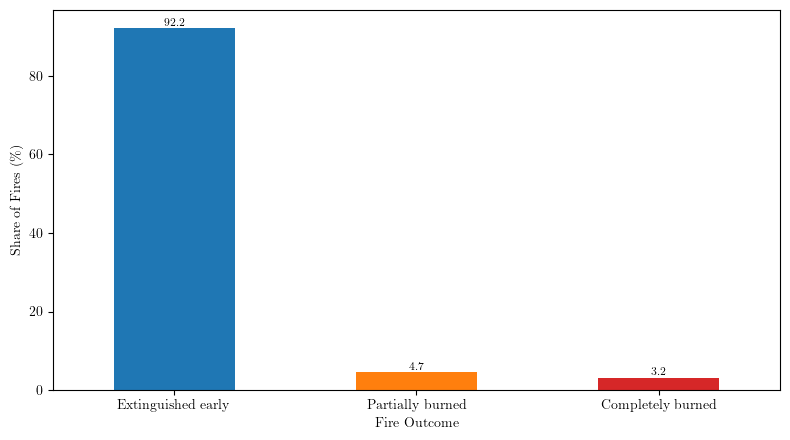

In [14]:
# 3a. class shares in the full data set
share = (y.value_counts(normalize=True).reindex(result_order) * 100)
print(share.round(1))

ax = share.plot(kind="bar", figsize=(8, 4.5), rot=0, color=["tab:blue", "tab:orange", "tab:red"])
ax.set_xlabel("Fire Outcome"); ax.set_ylabel(r"Share of Fires (\%)")
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.tight_layout()
plt.savefig("figures/class_imbalance.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
# 3b. LaTeX (pgfplots) version of the class-imbalance figure, same helper as outliers_pca.ipynb
def bars_to_latex(data, path, xlabel, ylabel, colors, decimals=1):
    cats = [str(c) for c in data.index]
    ymax = float(np.ceil(data.values.max() * 1.15))
    L = ["{%", r"\begin{tikzpicture}", r"\begin{axis}[",
         r"  width=\columnwidth, height=0.62\columnwidth,",
         rf"  ybar, bar width=12pt, ymin=0, ymax={ymax:g},",
         r"  symbolic x coords={" + ",".join(cats) + "}, xtick=data,",
         r"  enlarge x limits=0.25,",
         r"  xlabel={" + xlabel + "}, ylabel={" + ylabel + "},",
         r"  tick label style={font=\scriptsize}, label style={font=\small},",
         r"  nodes near coords={\pgfmathprintnumber[fixed,fixed zerofill,precision="
             + str(decimals) + r"]{\pgfplotspointmeta}},",
         r"  every node near coord/.append style={font=\tiny},",
         "]"]
    r, g, b = [[int(round(x * 255)) for x in mpl.colors.to_rgb(c)] for c in colors][0], None, None
    coords = " ".join(f"({cat},{v:.{decimals}f})" for cat, v in zip(cats, data.values))
    rgb_list = [mpl.colors.to_rgb(c) for c in colors]
    addplots = []
    for cat, v, c in zip(cats, data.values, rgb_list):
        rr, gg, bb = [int(round(x * 255)) for x in c]
        addplots.append(rf"\addplot[fill={{rgb,255:red,{rr};green,{gg};blue,{bb}}}, draw=none] coordinates {{({cat},{v:.{decimals}f})}};")
    L += addplots
    L += [r"\end{axis}", r"\end{tikzpicture}%", "}"]
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(L))
    print("Saved:", path)

bars_to_latex(share, "figures/class_imbalance.tex", xlabel="Fire Outcome",
              ylabel=r"Share of Fires (\%)", colors=["tab:blue", "tab:orange", "tab:red"])

Saved: figures/class_imbalance.tex


***4. Model Training***

In [16]:
# 4a. Decision Tree: tune max_depth on the validation set (macro F1, the metric that weighs
# minority classes equally with the majority class)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

depths = [3, 4, 5, 6, 8, 10, 12, None]
dt_scores = []
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=42)
    clf.fit(X_train, y_train)
    f1 = f1_score(y_val, clf.predict(X_val), average="macro")
    dt_scores.append(f1)
    print(f"max_depth={d}: val macro F1={f1:.3f}")

best_depth = depths[int(np.argmax(dt_scores))]
print("\nBest max_depth:", best_depth)

max_depth=3: val macro F1=0.368
max_depth=4: val macro F1=0.426
max_depth=5: val macro F1=0.459
max_depth=6: val macro F1=0.460
max_depth=8: val macro F1=0.526
max_depth=10: val macro F1=0.508
max_depth=12: val macro F1=0.536
max_depth=None: val macro F1=0.527

Best max_depth: 12


In [17]:
# 4b. final Decision Tree, fit on train, evaluated later on the untouched test set
dt_model = DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=12, random_state=42)

In [18]:
# 4c. Random Forest: tune n_estimators and max_depth on the validation set
n_estimators_grid = [100, 200, 400]
max_depth_grid = [8, 12, 16, None]
rf_results = []
for n in n_estimators_grid:
    for d in max_depth_grid:
        clf = RandomForestClassifier(n_estimators=n, max_depth=d, class_weight="balanced", random_state=42, n_jobs=-1)
        clf.fit(X_train, y_train)
        f1 = f1_score(y_val, clf.predict(X_val), average="macro")
        rf_results.append((n, d, f1))

rf_results_df = pd.DataFrame(rf_results, columns=["n_estimators", "max_depth", "val_macro_f1"])
print(rf_results_df.sort_values("val_macro_f1", ascending=False).to_string(index=False))

best_n, best_d, _ = max(rf_results, key=lambda r: r[2])
print("\nBest n_estimators:", best_n, " Best max_depth:", best_d)

 n_estimators  max_depth  val_macro_f1
          200       16.0      0.601685
          400       16.0      0.600940
          100       16.0      0.597435
          100       12.0      0.569261
          400       12.0      0.568521
          200       12.0      0.568044
          100        8.0      0.543273
          400        8.0      0.540234
          200        8.0      0.539829
          200        NaN      0.535867
          100        NaN      0.532491
          400        NaN      0.531764

Best n_estimators: 200  Best max_depth: 16


In [19]:
# 4d. final Random Forest, fit on train, evaluated later on the untouched test set
rf_model = RandomForestClassifier(n_estimators=best_n, max_depth=best_d, class_weight="balanced",
                                   random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=16, n_estimators=200,
                       n_jobs=-1, random_state=42)

***5. Evaluation on the Test Set***

In [20]:
# 5a. accuracy, precision, recall, F1 (macro and per-class) for both models
from sklearn.metrics import accuracy_score, classification_report, precision_recall_fscore_support

models = {"Decision Tree": dt_model, "Random Forest": rf_model}
summary_rows = []
reports = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, y_pred, labels=result_order, average=None, zero_division=0)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0)
    reports[name] = classification_report(y_test, y_pred, labels=result_order, zero_division=0)
    summary_rows.append({"Model": name, "Accuracy": acc, "Macro Precision": macro_p,
                          "Macro Recall": macro_r, "Macro F1": macro_f1})
    for cls, p, r, f in zip(result_order, precision, recall, f1):
        summary_rows[-1][f"{cls} Precision"] = p
        summary_rows[-1][f"{cls} Recall"] = r
        summary_rows[-1][f"{cls} F1"] = f

for name, report in reports.items():
    print(f"=== {name} ===")
    print(report)

=== Decision Tree ===
                    precision    recall  f1-score   support

Extinguished early       0.99      0.87      0.92      5869
  Partially burned       0.22      0.63      0.32       297
 Completely burned       0.30      0.54      0.39       203

          accuracy                           0.84      6369
         macro avg       0.50      0.68      0.54      6369
      weighted avg       0.93      0.84      0.88      6369

=== Random Forest ===
                    precision    recall  f1-score   support

Extinguished early       0.97      0.96      0.96      5869
  Partially burned       0.36      0.49      0.42       297
 Completely burned       0.48      0.47      0.48       203

          accuracy                           0.92      6369
         macro avg       0.61      0.64      0.62      6369
      weighted avg       0.93      0.92      0.92      6369



In [21]:
# 5b. comparison table: overall + per-class metrics (per-class is where minority performance shows up)
summary = pd.DataFrame(summary_rows).set_index("Model")
pd.set_option("display.width", 160)
print(summary.round(3).T)

Model                         Decision Tree  Random Forest
Accuracy                              0.844          0.918
Macro Precision                       0.502          0.606
Macro Recall                          0.680          0.640
Macro F1                              0.544          0.620
Extinguished early Precision          0.990          0.972
Extinguished early Recall             0.866          0.955
Extinguished early F1                 0.924          0.963
Partially burned Precision            0.216          0.365
Partially burned Recall               0.633          0.492
Partially burned F1                   0.322          0.419
Completely burned Precision           0.300          0.480
Completely burned Recall              0.542          0.473
Completely burned F1                  0.386          0.476


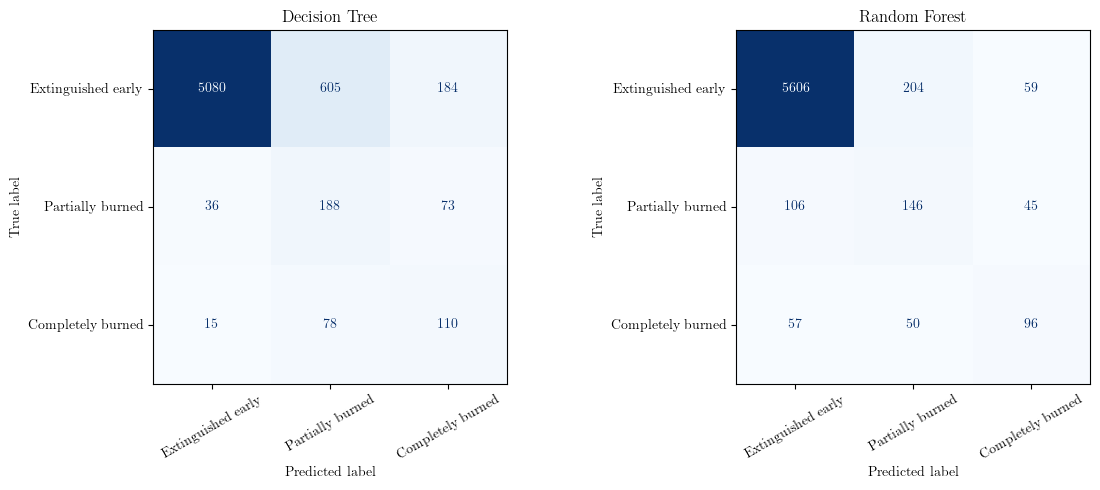

In [22]:
# 5c. confusion matrices
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=result_order)
    disp = ConfusionMatrixDisplay(cm, display_labels=result_order)
    disp.plot(ax=ax, colorbar=False, xticks_rotation=30, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

***6. Decision Tree Visualization***

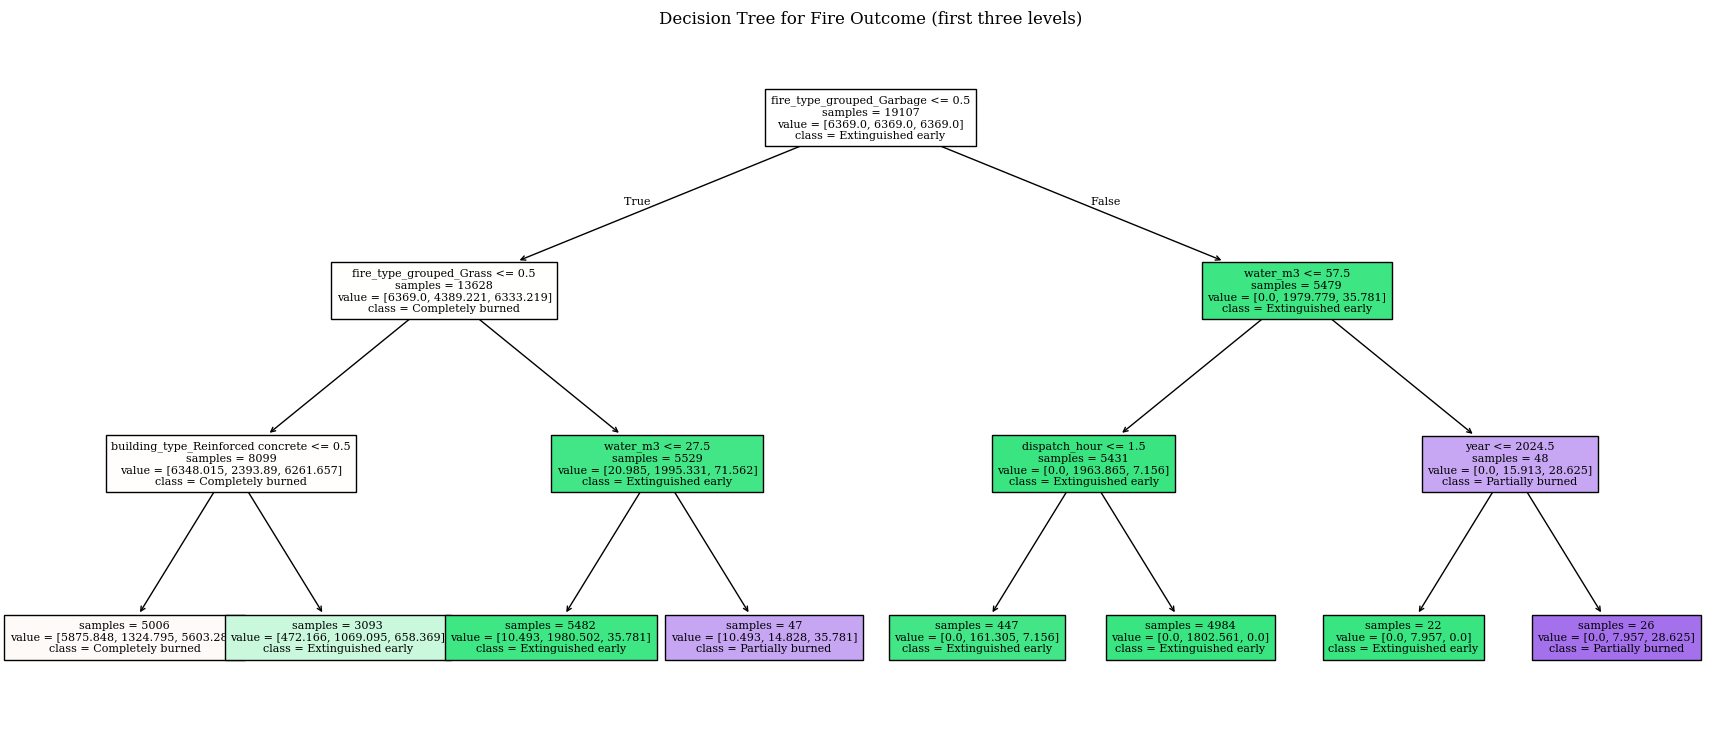

In [23]:
# 6a. shallow version of the tuned tree (max_depth=3), for a readable figure only -- the model
# actually evaluated above used best_depth, this is a separate, shallower tree fit purely for display
from sklearn.tree import plot_tree

plt.rcParams["text.usetex"] = False  # feature names contain "_", which LaTeX cannot print directly
dt_display = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42)
dt_display.fit(X_train, y_train)

# class_names must follow the model's own class order (alphabetical), not result_order
plt.figure(figsize=(22, 9))
plot_tree(dt_display, max_depth=3, feature_names=X.columns, class_names=list(dt_display.classes_),
          filled=True, impurity=False, fontsize=8)
plt.title("Decision Tree for Fire Outcome (first three levels)")
plt.savefig("figures/dt_classification.png", dpi=300, bbox_inches="tight")
plt.show()
plt.rcParams["text.usetex"] = True

In [24]:
import time
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (f1_score, accuracy_score, precision_recall_fscore_support,
                             classification_report, recall_score)

skewed = ["water_m3", "foam_kg", "dry_powder_kg", "arrival_min",
          "human_deaths", "human_injured", "animal_deaths"]
scale_cols = numeric_features  # the 10 numeric attributes

def svm_prepare(X_fit, *others):
    """log1p + standardize numeric columns; scaler is fit on X_fit only."""
    def logt(Xp):
        Xp = Xp.astype(float).copy()
        Xp[skewed] = np.log1p(Xp[skewed].clip(lower=0))
        return Xp
    X_fit = logt(X_fit)
    scaler = StandardScaler().fit(X_fit[scale_cols])
    out = []
    for Xp in (X_fit,) + others:
        Xp = Xp if Xp is X_fit else logt(Xp)
        Xp = Xp.copy()
        Xp[scale_cols] = scaler.transform(Xp[scale_cols])
        out.append(Xp)
    return out

y_train_s, y_val_s, y_test_s = y_train.astype(str), y_val.astype(str), y_test.astype(str)
X_train_s, X_val_s, X_test_s = svm_prepare(X_train, X_val, X_test)
print(X_train_s.shape, X_val_s.shape, X_test_s.shape)

(19107, 42) (6369, 42) (6369, 42)


In [25]:
C_grid = [0.1, 1, 10, 100]
gamma_grid = [0.001, 0.01, 0.1, 1]
svm_results = []
for C in C_grid:
    for g in gamma_grid:
        t0 = time.time()
        clf = SVC(kernel="rbf", C=C, gamma=g, class_weight="balanced",
                  cache_size=1000, random_state=42)
        clf.fit(X_train_s, y_train_s)
        f1 = f1_score(y_val_s, clf.predict(X_val_s), average="macro")
        svm_results.append((C, g, f1))
        print(f"C={C:<6} gamma={g:<6} val macro F1={f1:.3f}  ({time.time()-t0:.0f}s)")

svm_results_df = pd.DataFrame(svm_results, columns=["C", "gamma", "val_macro_f1"])
best_C, best_gamma, best_f1_cw = max(svm_results, key=lambda r: r[2])
print(f"\nBest C={best_C}, gamma={best_gamma}, val macro F1={best_f1_cw:.3f}")

C=0.1    gamma=0.001  val macro F1=0.474  (109s)
C=0.1    gamma=0.01   val macro F1=0.484  (46s)
C=0.1    gamma=0.1    val macro F1=0.500  (32s)
C=0.1    gamma=1      val macro F1=0.439  (71s)
C=1      gamma=0.001  val macro F1=0.489  (41s)
C=1      gamma=0.01   val macro F1=0.513  (24s)
C=1      gamma=0.1    val macro F1=0.532  (24s)
C=1      gamma=1      val macro F1=0.493  (38s)
C=10     gamma=0.001  val macro F1=0.514  (26s)
C=10     gamma=0.01   val macro F1=0.524  (20s)
C=10     gamma=0.1    val macro F1=0.549  (15s)
C=10     gamma=1      val macro F1=0.486  (33s)
C=100    gamma=0.001  val macro F1=0.530  (22s)
C=100    gamma=0.01   val macro F1=0.527  (23s)
C=100    gamma=0.1    val macro F1=0.530  (15s)
C=100    gamma=1      val macro F1=0.474  (34s)

Best C=10, gamma=0.1, val macro F1=0.549


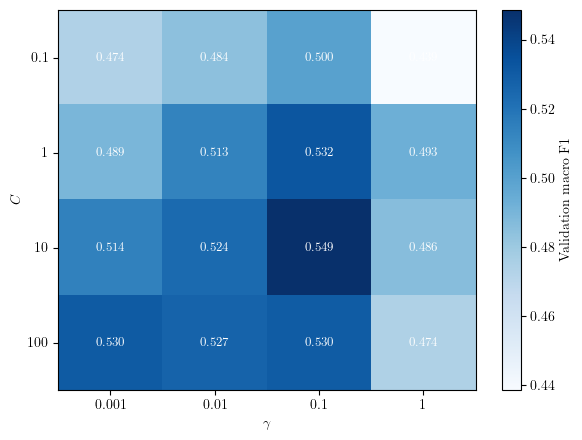

In [26]:
heat = svm_results_df.pivot(index="C", columns="gamma", values="val_macro_f1")
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels([f"{g:g}" for g in heat.columns])
ax.set_yticks(range(len(heat.index)));   ax.set_yticklabels([f"{c:g}" for c in heat.index])
ax.set_xlabel(r"$\gamma$"); ax.set_ylabel(r"$C$")
vmax = np.nanmax(heat.values)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.75 * vmax else "black")
fig.colorbar(im, ax=ax, label="Validation macro F1")
plt.tight_layout()
plt.savefig("figures/svm_grid.png", dpi=300, bbox_inches="tight")
plt.show()

In [27]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(15).round(3))

fs_results = []
for k in [k for k in [10, 20, 30] if k < len(X.columns)] + [len(X.columns)]:
    cols = importances.index[:k].tolist()
    clf = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced",
              cache_size=1000, random_state=42)
    clf.fit(X_train_s[cols], y_train_s)
    f1 = f1_score(y_val_s, clf.predict(X_val_s[cols]), average="macro")
    fs_results.append((k, f1))
    print(f"top-{k} features: val macro F1={f1:.3f}")

# keep the full set unless a smaller set is clearly better (> 0.005), for comparability with DT/RF
best_k, best_k_f1 = max(fs_results, key=lambda r: r[1])
full_f1 = dict(fs_results)[len(X.columns)]
if best_k < len(X.columns) and best_k_f1 - full_f1 > 0.005:
    selected_cols = importances.index[:best_k].tolist()
else:
    selected_cols = X.columns.tolist()
print("Selected number of features:", len(selected_cols))

water_m3                                       0.177
dispatch_hour                                  0.086
arrival_min                                    0.079
fire_type_grouped_Garbage                      0.074
fire_type_grouped_Grass                        0.073
month                                          0.071
fire_type_grouped_Other                        0.047
fire_type_grouped_Vehicle                      0.043
fire_cause_grouped_Cigarette/match             0.037
fire_cause_grouped_Electrical short circuit    0.026
foam_kg                                        0.023
fire_cause_grouped_Open fire                   0.023
building_type_Reinforced concrete              0.021
year                                           0.021
building_type_Not applicable                   0.018
dtype: float64
top-10 features: val macro F1=0.499
top-20 features: val macro F1=0.515
top-30 features: val macro F1=0.544
top-42 features: val macro F1=0.549
Selected number of features: 42


In [28]:
from imblearn.over_sampling import SMOTENC

raw_cols = numeric_features + categorical_features + ["iso_outlier"]
X_raw = df[numeric_features + categorical_features].copy()
X_raw["iso_outlier"] = df["iso_outlier"].astype(int)
X_raw_train = X_raw.loc[X_train.index]
cat_idx = [raw_cols.index(c) for c in categorical_features + ["iso_outlier"]]
int_cols = ["human_deaths", "human_injured", "animal_deaths", "year", "month", "dispatch_hour"]

def smotenc_train(strategy):
    sm = SMOTENC(categorical_features=cat_idx, sampling_strategy=strategy,
                 random_state=42, k_neighbors=5)
    Xr, yr = sm.fit_resample(X_raw_train, y_train_s)
    Xr = pd.DataFrame(Xr, columns=raw_cols)
    Xr[int_cols] = Xr[int_cols].astype(float).round().astype(int)   # no fractional deaths
    Xr[numeric_features] = Xr[numeric_features].astype(float)
    Xr = pd.get_dummies(Xr, columns=categorical_features).reindex(columns=X.columns, fill_value=0)
    return Xr, pd.Series(yr)

n_major = (y_train_s == "Extinguished early").sum()
strategies = {
    "SMOTENC (full)": "auto",                                      # minorities -> majority size
    "SMOTENC (25%)":  {"Partially burned": int(0.25 * n_major),    # milder: minorities -> 25% of majority
                       "Completely burned": int(0.25 * n_major)},
}

imb_rows = [("Class weights", best_C, best_f1_cw if len(selected_cols) == len(X.columns) else best_k_f1,
             None)]
imb_models = {}
for sname, strat in strategies.items():
    Xr, yr = smotenc_train(strat)
    synth_share = 1 - len(X_train) / len(Xr)
    print(f"\n{sname}: {len(Xr)} training rows, {synth_share:.0%} synthetic")
    Xr_s, Xv_s = svm_prepare(Xr, X_val)
    best = None
    for C in sorted({best_C / 10, best_C, best_C * 10}):   # small grid around the best C
        t0 = time.time()
        clf = SVC(kernel="rbf", C=C, gamma=best_gamma, cache_size=2000, random_state=42)
        clf.fit(Xr_s[selected_cols], yr)
        f1 = f1_score(y_val_s, clf.predict(Xv_s[selected_cols]), average="macro")
        print(f"  C={C:<7g} val macro F1={f1:.3f}  ({time.time()-t0:.0f}s)")
        if best is None or f1 > best[1]:
            best = (C, f1)
    imb_rows.append((sname, best[0], best[1], f"{synth_share:.0%}"))

imb_df = pd.DataFrame(imb_rows, columns=["Strategy", "C", "val_macro_f1", "synthetic_share"])
print("\n", imb_df.to_string(index=False))
best_strategy = imb_df.loc[imb_df["val_macro_f1"].idxmax(), "Strategy"]
print("Chosen strategy:", best_strategy)


SMOTENC (full): 52830 training rows, 64% synthetic
  C=1       val macro F1=0.552  (170s)
  C=10      val macro F1=0.541  (142s)
  C=100     val macro F1=0.536  (163s)

SMOTENC (25%): 26414 training rows, 28% synthetic
  C=1       val macro F1=0.576  (30s)
  C=10      val macro F1=0.560  (29s)
  C=100     val macro F1=0.543  (35s)

       Strategy    C  val_macro_f1 synthetic_share
 Class weights 10.0      0.548581            None
SMOTENC (full)  1.0      0.552048             64%
 SMOTENC (25%)  1.0      0.576428             28%
Chosen strategy: SMOTENC (25%)


In [29]:
final_C = float(imb_df.loc[imb_df["Strategy"] == best_strategy, "C"].iloc[0])
if best_strategy == "Class weights":
    Xf_s, Xt_s = X_train_s, X_test_s
    yf, cw = y_train_s, "balanced"
else:
    Xr, yf = smotenc_train(strategies[best_strategy])
    Xf_s, Xt_s = svm_prepare(Xr, X_test)
    cw = None

svm_model = SVC(kernel="rbf", C=final_C, gamma=best_gamma, class_weight=cw,
                cache_size=2000, random_state=42)
svm_model.fit(Xf_s[selected_cols], yf)
y_pred_svm = svm_model.predict(Xt_s[selected_cols])
print(f"Final SVM: C={final_C}, gamma={best_gamma}, strategy={best_strategy}, "
      f"features={len(selected_cols)}, support vectors={svm_model.n_support_.sum()}")
print(classification_report(y_test_s, y_pred_svm, labels=result_order, zero_division=0))

Final SVM: C=1.0, gamma=0.1, strategy=SMOTENC (25%), features=42, support vectors=8889
                    precision    recall  f1-score   support

Extinguished early       0.97      0.95      0.96      5869
  Partially burned       0.34      0.43      0.38       297
 Completely burned       0.38      0.54      0.45       203

          accuracy                           0.91      6369
         macro avg       0.56      0.64      0.60      6369
      weighted avg       0.93      0.91      0.92      6369



In [30]:
acc = accuracy_score(y_test_s, y_pred_svm)
p, r, f, _ = precision_recall_fscore_support(y_test_s, y_pred_svm, labels=result_order,
                                             average=None, zero_division=0)
mp, mr, mf, _ = precision_recall_fscore_support(y_test_s, y_pred_svm, average="macro", zero_division=0)
svm_row = {"Model": "SVM", "Accuracy": acc, "Macro Precision": mp, "Macro Recall": mr, "Macro F1": mf}
for cls, pp, rr, ff in zip(result_order, p, r, f):
    svm_row[f"{cls} Precision"], svm_row[f"{cls} Recall"], svm_row[f"{cls} F1"] = pp, rr, ff

rows_all = [row for row in summary_rows if row["Model"] != "SVM"] + [svm_row]
summary3 = pd.DataFrame(rows_all).set_index("Model")
print(summary3.round(3).T)

# LaTeX version of Table I with three model columns (best value per row in bold)
def table_to_latex(s, path):
    models_ = s.index.tolist()
    groups = [("All", [("Accuracy", "Accuracy"), ("Macro precision", "Macro Precision"),
                       ("Macro recall", "Macro Recall"), ("Macro F1", "Macro F1")])]
    for cls in result_order:
        groups.append((cls, [("Precision", f"{cls} Precision"), ("Recall", f"{cls} Recall"),
                             ("F1", f"{cls} F1")]))
    L = [r"\begin{table}[htbp]", r"\caption{Classification results on the test set}",
         r"\label{tab:classification}", r"\centering", r"\setlength{\tabcolsep}{4pt}",
         r"\begin{tabular}{ll" + "r" * len(models_) + "}", r"\hline",
         r"\textbf{Class} & \textbf{Metric} & " + " & ".join(rf"\textbf{{{m}}}" for m in models_) + r" \\",
         r"\hline"]
    for cls, metrics in groups:
        words = cls.split(" ", 1)
        for i, (label, col) in enumerate(metrics):
            vals = s[col].round(3)
            cells = [rf"\textbf{{{v:.3f}}}" if v == vals.max() else f"{v:.3f}" for v in vals]
            first = words[i] if i < len(words) else ""
            L.append(f"{first} & {label} & " + " & ".join(cells) + r" \\")
        L.append(r"\hline")
    L += [r"\end{tabular}", r"\end{table}"]
    with open(path, "w", encoding="utf-8") as fh:
        fh.write("\n".join(L))
    print("Saved:", path)

table_to_latex(summary3, "figures/classification_table.tex")

Model                         Decision Tree  Random Forest    SVM
Accuracy                              0.844          0.918  0.909
Macro Precision                       0.502          0.606  0.564
Macro Recall                          0.680          0.640  0.639
Macro F1                              0.544          0.620  0.595
Extinguished early Precision          0.990          0.972  0.974
Extinguished early Recall             0.866          0.955  0.946
Extinguished early F1                 0.924          0.963  0.960
Partially burned Precision            0.216          0.365  0.337
Partially burned Recall               0.633          0.492  0.434
Partially burned F1                   0.322          0.419  0.379
Completely burned Precision           0.300          0.480  0.381
Completely burned Recall              0.542          0.473  0.537
Completely burned F1                  0.386          0.476  0.446
Saved: figures/classification_table.tex


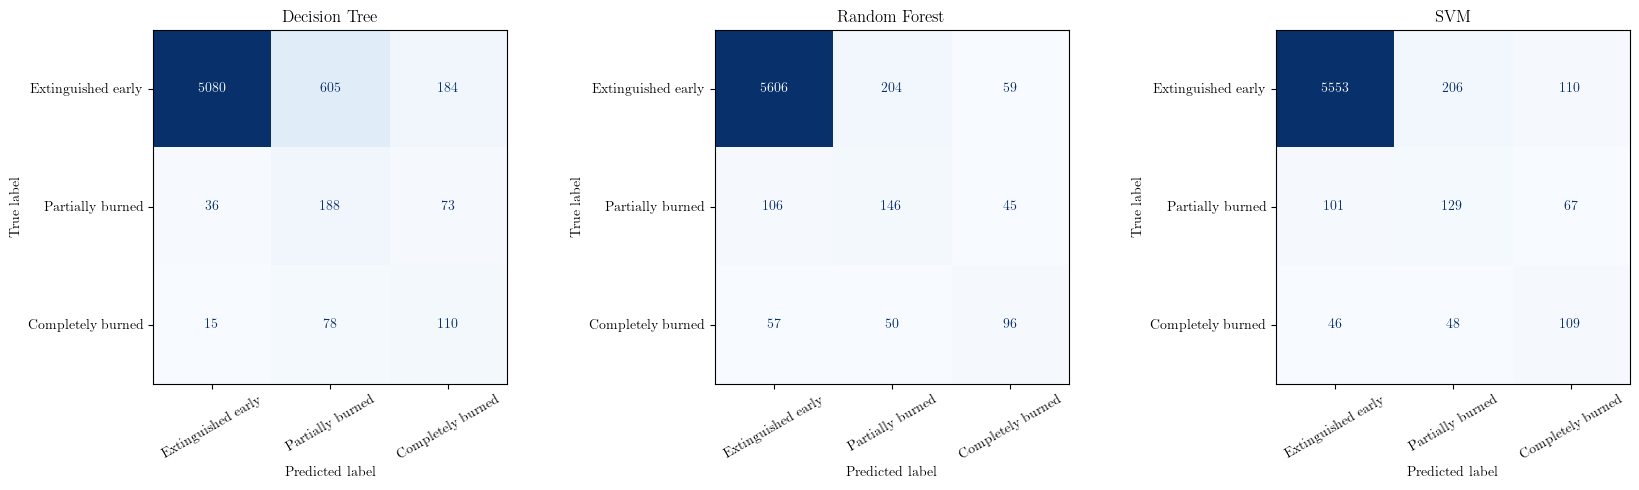

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

preds = {"Decision Tree": dt_model.predict(X_test).astype(str),
         "Random Forest": rf_model.predict(X_test).astype(str),
         "SVM": y_pred_svm}
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, yp) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test_s, yp, labels=result_order)
    ConfusionMatrixDisplay(cm, display_labels=result_order).plot(
        ax=ax, colorbar=False, xticks_rotation=30, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/confusion_matrices_3models.png", dpi=300, bbox_inches="tight")
plt.show()

In [32]:
print("SVM grid (class weights):\n", svm_results_df.round(3).to_string(index=False))
print("\nFeature selection:", [(k, round(v, 3)) for k, v in fs_results])
print("\nImbalance strategies:\n", imb_df.round(3).to_string(index=False))
print("\nFinal:", dict(C=final_C, gamma=best_gamma, strategy=best_strategy,
                      n_features=len(selected_cols), n_SV=int(svm_model.n_support_.sum())))
print("\nTest results:\n", summary3.round(3).T.to_string())

SVM grid (class weights):
     C  gamma  val_macro_f1
  0.1  0.001         0.474
  0.1  0.010         0.484
  0.1  0.100         0.500
  0.1  1.000         0.439
  1.0  0.001         0.489
  1.0  0.010         0.513
  1.0  0.100         0.532
  1.0  1.000         0.493
 10.0  0.001         0.514
 10.0  0.010         0.524
 10.0  0.100         0.549
 10.0  1.000         0.486
100.0  0.001         0.530
100.0  0.010         0.527
100.0  0.100         0.530
100.0  1.000         0.474

Feature selection: [(10, 0.499), (20, 0.515), (30, 0.544), (42, 0.549)]

Imbalance strategies:
       Strategy    C  val_macro_f1 synthetic_share
 Class weights 10.0         0.549            None
SMOTENC (full)  1.0         0.552             64%
 SMOTENC (25%)  1.0         0.576             28%

Final: {'C': 1.0, 'gamma': 0.1, 'strategy': 'SMOTENC (25%)', 'n_features': 42, 'n_SV': 8889}

Test results:
 Model                         Decision Tree  Random Forest    SVM
Accuracy                              0.8